Test accuracy: 84.62%
Test loss: 0.15


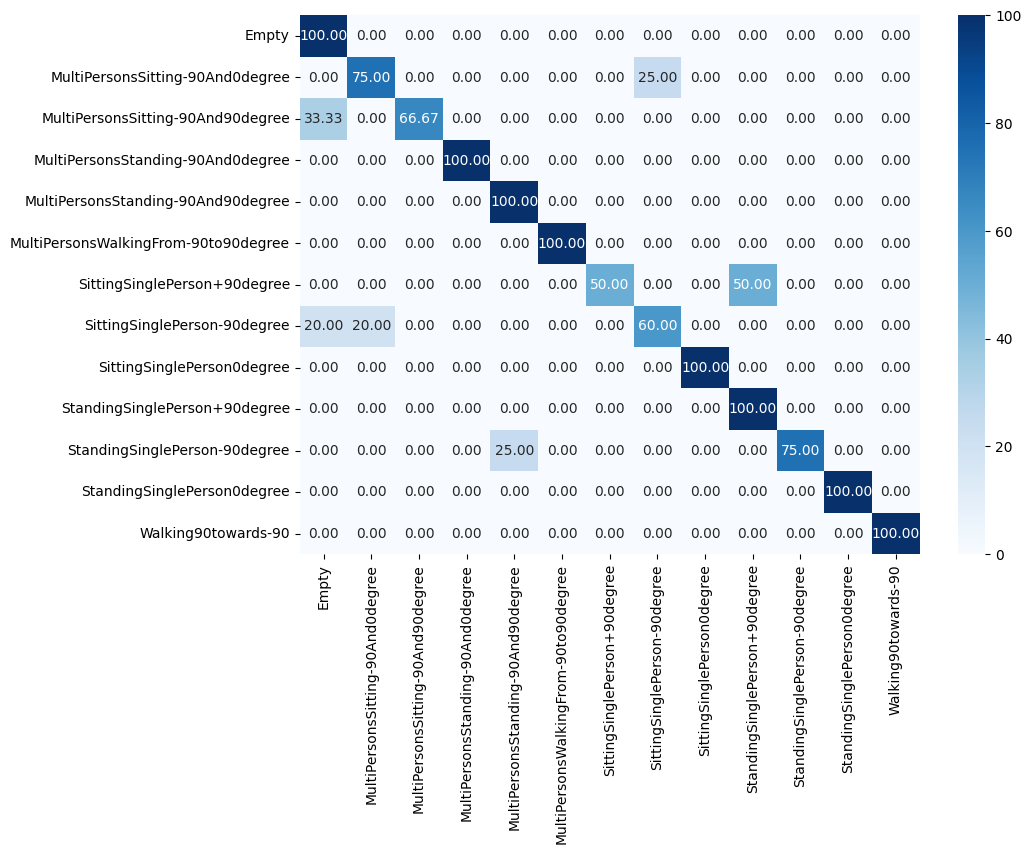

In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Load the dataset (replace 'your_data.csv' with the path to your dataset)
data = pd.read_csv('/content/data.csv')

# Separate features and target
X = data.iloc[:, :-1].values  # all columns except the last one
y = data.iloc[:, -1].values   # the last column

# Encode the labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.3, random_state=42)

# Feature scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Train the SVM
svm_model = SVC(kernel='linear', random_state=42)
svm_model.fit(X_train, y_train)

# Predict the test set results
y_pred = svm_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Test accuracy: {accuracy*100:.2f}%")

# Assuming loss as 1 - accuracy
loss = 1 - accuracy
print(f"Test loss: {loss:.2f}")

# Decode the encoded labels back to original labels for confusion matrix
y_test_labels = label_encoder.inverse_transform(y_test)
y_pred_labels = label_encoder.inverse_transform(y_pred)

# Generate confusion matrix
cm = confusion_matrix(y_test_labels, y_pred_labels)

# Convert confusion matrix to percentages
cm_percentage = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

# Turn the confusion matrix into a DataFrame
cm_df_percentage = pd.DataFrame(cm_percentage, index=label_encoder.classes_, columns=label_encoder.classes_)

# Heatmap visualization
plt.figure(figsize=(10,7))
sns.heatmap(cm_df_percentage, annot=True, fmt='.2f', cmap='Blues')
#plt.title('Confusion Matrix Heatmap (Percentage)')
plt.savefig("ConfusionMatrix",bbox_inches='tight',dpi=300)
plt.show()
